In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
calendar = pd.read_csv("../data/raw/calendar.csv")
sales = pd.read_csv("../data/raw/sales_train_evaluation.csv")
prices = pd.read_csv("../data/raw/sell_prices.csv")

print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1947)
Prices: (6841121, 4)


In [4]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [5]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


In [6]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [7]:
print("CALENDAR")
print(calendar.columns.tolist())

print("\nSALES")
print(sales.columns.tolist())

print("\nPRICES")
print(prices.columns.tolist())

CALENDAR
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

SALES
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_

In [8]:
sales[[
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]].nunique()

item_id     3049
dept_id        7
cat_id         3
store_id      10
state_id       3
dtype: int64

In [9]:
calendar["date"] = pd.to_datetime(calendar["date"])

print("Start:", calendar["date"].min())
print("End:", calendar["date"].max())

Start: 2011-01-29 00:00:00
End: 2016-06-19 00:00:00


In [10]:
calendar.isna().sum().sort_values(ascending=False).head(15)

event_type_2    1964
event_name_2    1964
event_name_1    1807
event_type_1    1807
date               0
wm_yr_wk           0
year               0
month              0
wday               0
weekday            0
d                  0
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

In [11]:
sales.isna().sum().sort_values(ascending=False).head(15)

id          0
item_id     0
dept_id     0
cat_id      0
store_id    0
state_id    0
d_1         0
d_2         0
d_3         0
d_4         0
d_5         0
d_6         0
d_7         0
d_8         0
d_9         0
dtype: int64

In [12]:
prices.isna().sum().sort_values(ascending=False).head(15)

store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

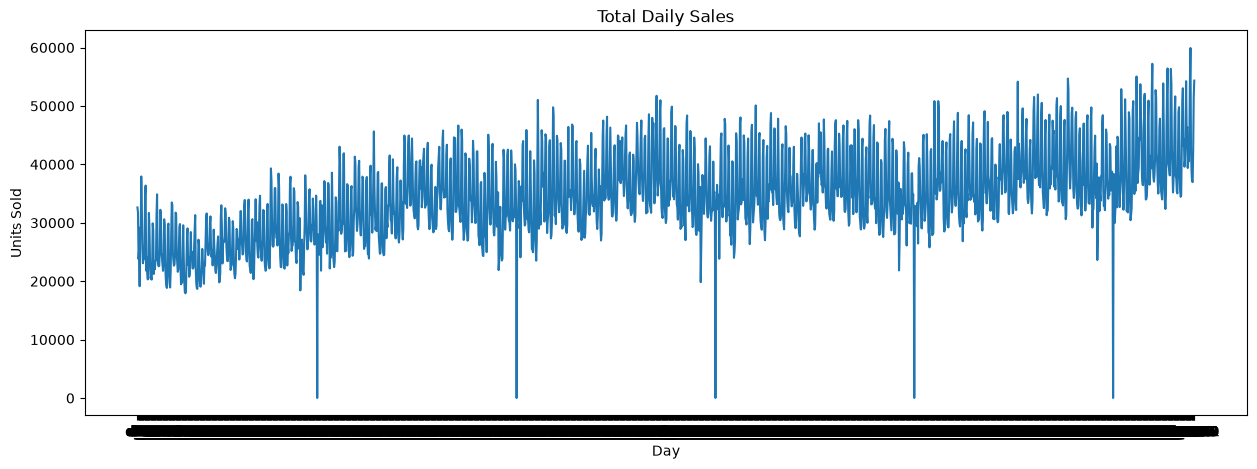

In [24]:
daily_sales = sales.filter(like="d_").sum()

plt.figure(figsize=(15, 5))

plt.plot(daily_sales)

plt.title("Total Daily Sales")
plt.xlabel("Day")
plt.ylabel("Units Sold")

plt.show()

In [15]:
print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

print(sales[[
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]].nunique())

print("Start:", calendar["date"].min())
print("End:", calendar["date"].max())

Calendar: (1969, 14)
Sales: (30490, 1947)
Prices: (6841121, 4)
item_id     3049
dept_id        7
cat_id         3
store_id      10
state_id       3
dtype: int64
Start: 2011-01-29 00:00:00
End: 2016-06-19 00:00:00


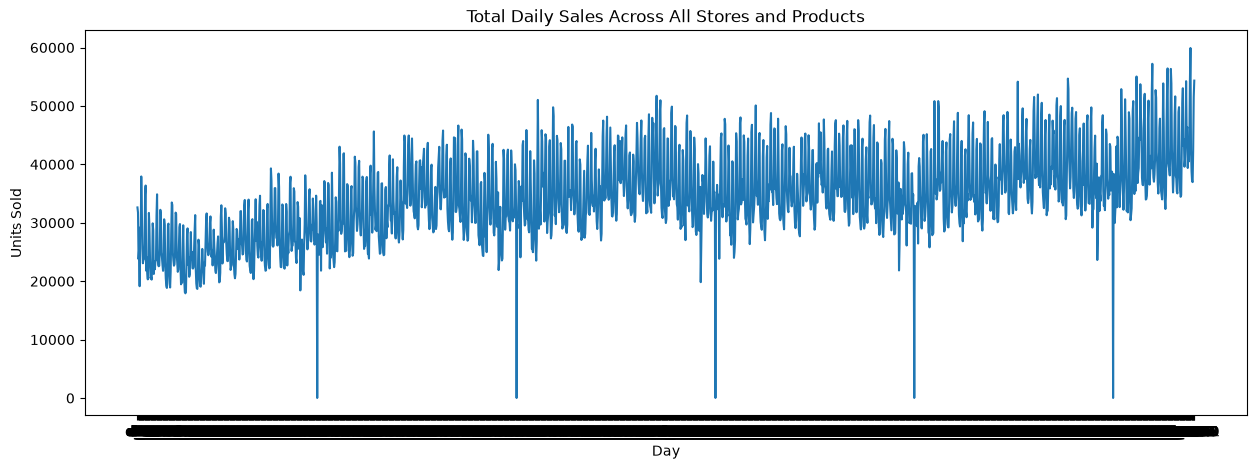

In [16]:
daily_sales = sales.filter(like="d_").sum()

plt.figure(figsize=(15, 5))
plt.plot(daily_sales)

plt.title("Total Daily Sales Across All Stores and Products")
plt.xlabel("Day")
plt.ylabel("Units Sold")

plt.show()

In [17]:
daily_sales.describe()

count     1941.000000
mean     34480.769191
std       7425.906822
min         11.000000
25%      29713.000000
50%      33830.000000
75%      39008.000000
max      59921.000000
dtype: float64

In [19]:
category_sales = sales.groupby("cat_id")[sales.filter(like="d_").columns].sum()
category_sales.sum(axis=1).sort_values(ascending=False)

cat_id
FOODS        45922427
HOUSEHOLD    14764090
HOBBIES       6240656
dtype: int64

In [20]:
store_sales = sales.groupby("store_id")[sales.filter(like="d_").columns].sum()

store_sales.sum(axis=1).sort_values(ascending=False)

store_id
CA_3    11363540
CA_1     7832248
TX_2     7329642
WI_2     6697988
WI_3     6542557
TX_3     6205940
CA_2     5818395
TX_1     5692823
WI_1     5261506
CA_4     4182534
dtype: int64

day_of_week
Monday       32994.931408
Tuesday      30500.483755
Wednesday    30130.418773
Thursday     30321.039711
Friday       34357.472924
Saturday     41706.269784
Sunday       41304.050360
Name: sales, dtype: float64


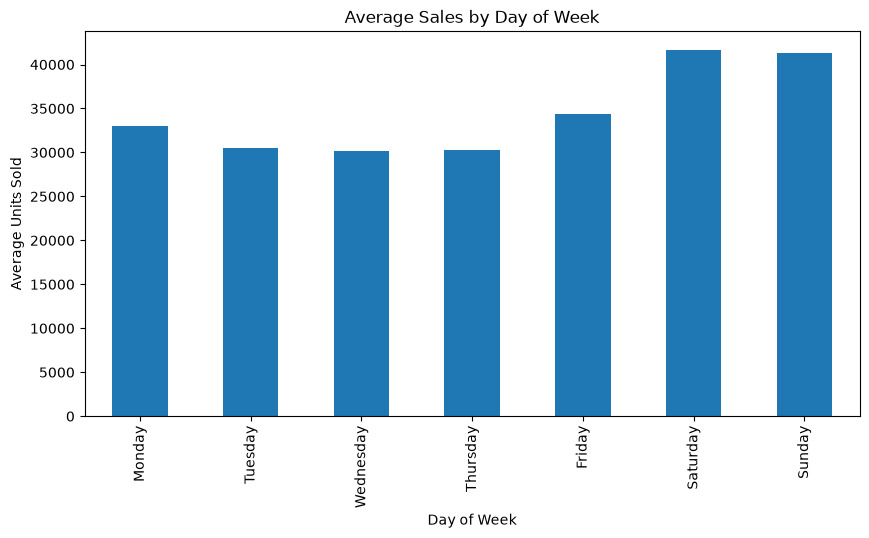

In [23]:
dates = calendar["date"].iloc[:len(daily_sales)]

daily_df = pd.DataFrame({
    "date": dates.values,
    "sales": daily_sales.values
})

daily_df["day_of_week"] = daily_df["date"].dt.day_name()

weekly_pattern = (
    daily_df
    .groupby("day_of_week")["sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

print(weekly_pattern)

weekly_pattern.plot(kind="bar", figsize=(10, 5))

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")

plt.show()

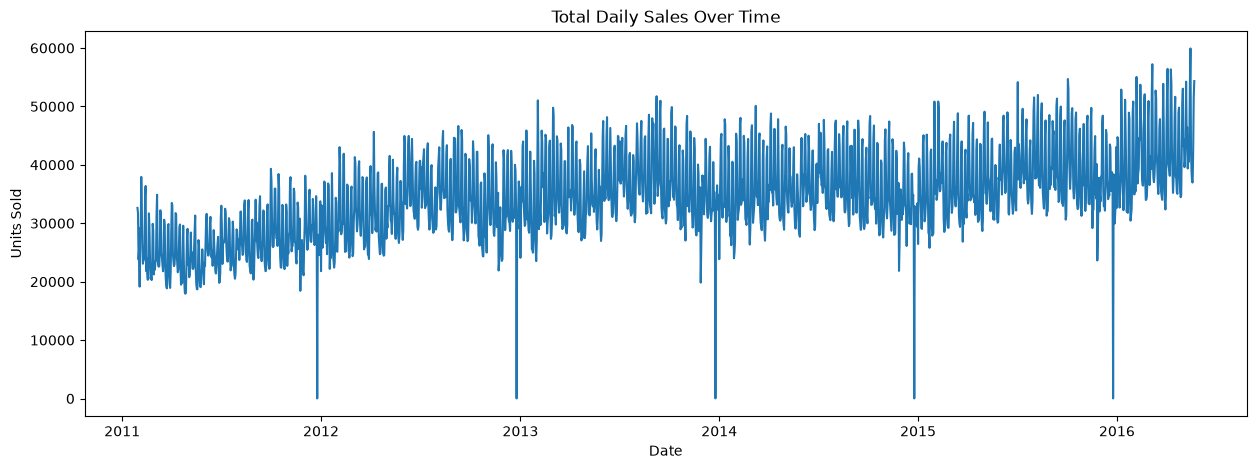

In [25]:
plt.figure(figsize=(15, 5))

plt.plot(daily_df["date"], daily_df["sales"])

plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.show()

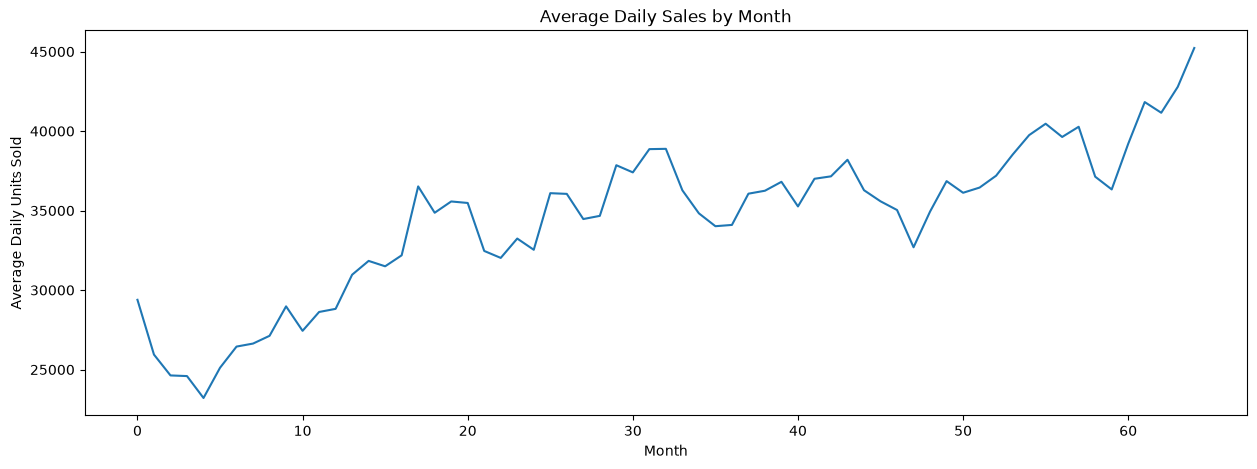

In [31]:
daily_df["year"] = daily_df["date"].dt.year
daily_df["month"] = daily_df["date"].dt.month

monthly_sales = (
    daily_df
    .groupby(["year", "month"])["sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(15, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales["sales"]
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Units Sold")

plt.show()

month
1     33832.348101
2     34644.641176
3     34339.838710
4     34432.183333
5     34085.192090
6     35001.413333
7     35122.419355
8     35946.645161
9     35479.260000
10    34713.477419
11    33290.826667
12    32980.464516
Name: sales, dtype: float64


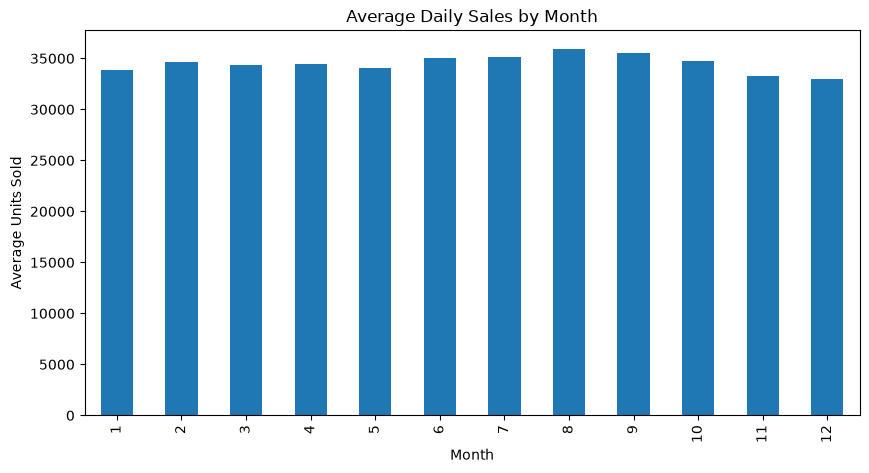

In [32]:
monthly_pattern = (
    daily_df
    .groupby("month")["sales"]
    .mean()
)

print(monthly_pattern)

monthly_pattern.plot(kind="bar", figsize=(10, 5))

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.show()

In [29]:
calendar[
    calendar["event_name_1"].notna()
][[
    "date",
    "event_name_1",
    "event_type_1"
]].head(20)

calendar["event_name_1"].value_counts().head(15)

calendar["event_type_1"].value_counts()

event_type_1
Religious    55
National     52
Cultural     37
Sporting     18
Name: count, dtype: int64

In [34]:
event_calendar = calendar[[
    "date",
    "event_name_1",
    "event_type_1"
]].copy()

daily_events = daily_df.merge(
    event_calendar,
    on="date",
    how="left"
)

daily_events["is_event"] = daily_events["event_name_1"].notna()

event_comparison = (
    daily_events
    .groupby("is_event")["sales"]
    .agg(["mean", "median", "count"])
)

event_comparison

,mean,median,count
is_event,,,
False,34609.336511,33817.0,1783
True,33029.911392,33956.5,158


In [35]:
event_type_sales = (
    daily_events[
        daily_events["event_type_1"].notna()
    ]
    .groupby("event_type_1")["sales"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

event_type_sales

,mean,median,count
event_type_1,,,
Sporting,35796.062500,34998.0,16
Cultural,34718.594595,35820.0,37
Religious,34426.240741,34214.0,54
National,29458.509804,32656.0,51


In [36]:
event_sales = (
    daily_events[
        daily_events["event_name_1"].notna()
    ]
    .groupby("event_name_1")["sales"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

event_sales.head(15)

,mean,median,count
event_name_1,,,
LaborDay,42154.600000,44525.0,5
OrthodoxEaster,41228.000000,43203.0,5
SuperBowl,40924.000000,40971.5,6
Easter,39517.600000,38934.0,5
Father's day,36562.000000,39364.5,4
Pesach End,36280.000000,36594.0,6
Mother's day,36111.000000,37710.0,6
Purim End,35957.000000,33411.0,6
Eid al-Fitr,35267.600000,34886.0,5


**Key Findings**
- Strong weekly seasonality: Weekend sales are substantially higher than weekday sales, with Saturday averaging ~41.7K units versus ~30.1K on Wednesday.
- Moderate annual seasonality: Sales peak around August–September and decline toward November–December.
- Store-level variation: Aggregate demand varies considerably across stores, indicating geographic/store effects are important.
- Category imbalance: FOODS generates substantially more demand than HOUSEHOLD and HOBBIES.
- Event effects are heterogeneous: Event days do not universally increase demand; national events show lower average sales while sporting events show higher average sales.
- Implication: These patterns motivate incorporating calendar, store, category, event, price, and lag-based features into the forecasting model.